# Notebook 01 — EDA
## STOP 1 — Load Dataset

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from sklearn.datasets import fetch_california_housing

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
CHARTS = ROOT / "charts"
CHARTS.mkdir(parents=True, exist_ok=True)

data = fetch_california_housing(as_frame=True)
df = data.frame.copy()
df.rename(columns={"MedHouseVal": "MedHouseVal"}, inplace=True)

print("shape:", df.shape)
print("\ndtypes:\n", df.dtypes)
print("\ndescribe:\n", df.describe())
df.head()

shape: (20640, 9)

dtypes:
 MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

describe:
              MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   
75%        4.743250     37.000000      6.052381      1.099526   1725.000000   
max       15.000100     52.000000    141.909091     34.066667  35682.000000   

           AveOccup      La

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## STOP 2 — Target Distribution

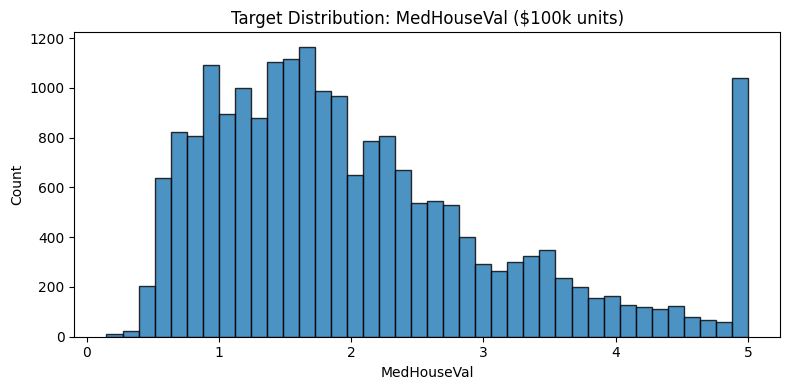

y.max() = 5.00001


In [2]:
y = df["MedHouseVal"]
plt.figure(figsize=(8,4))
plt.hist(y, bins=40, edgecolor="black", alpha=0.8)
plt.title("Target Distribution: MedHouseVal ($100k units)")
plt.xlabel("MedHouseVal")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(CHARTS / "target_distribution.png", dpi=180)
plt.show()
print("y.max() =", y.max())

## STOP 3 — Feature-Target Relationships

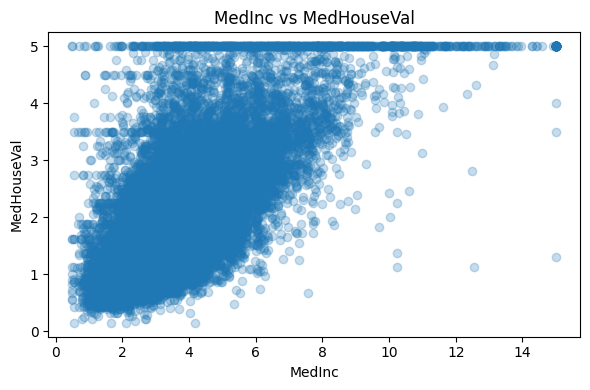

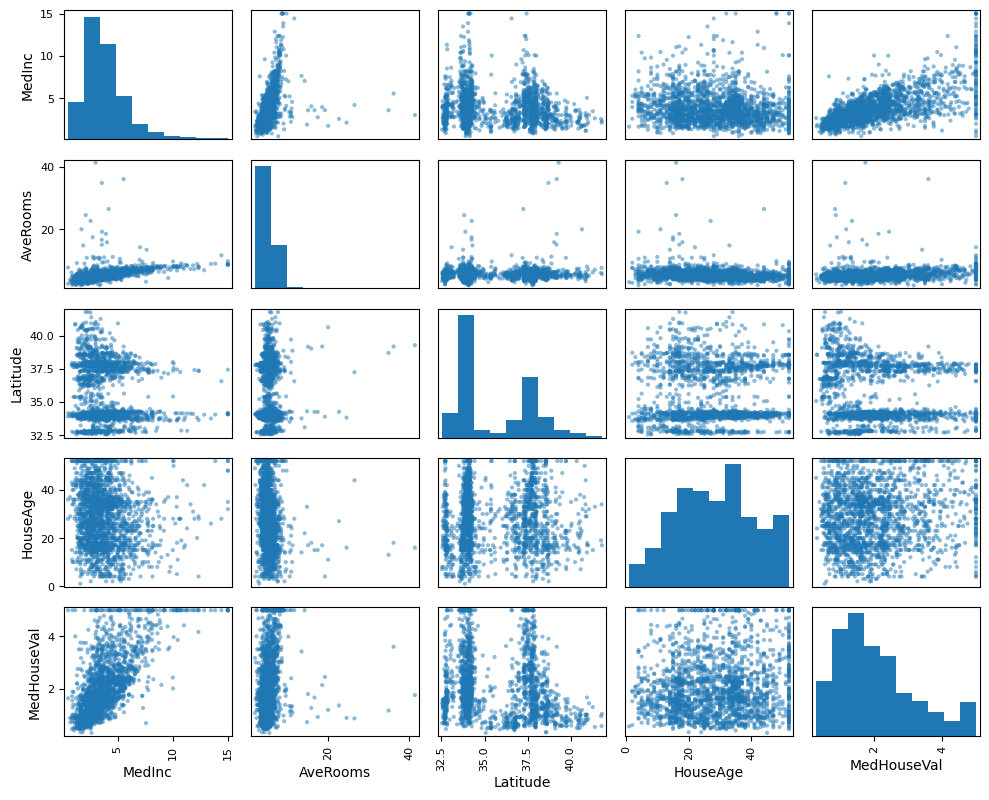

Top correlated features: ['MedInc', 'AveRooms', 'Latitude', 'HouseAge']


In [3]:
plt.figure(figsize=(6,4))
plt.scatter(df["MedInc"], df["MedHouseVal"], alpha=0.25)
plt.title("MedInc vs MedHouseVal")
plt.xlabel("MedInc")
plt.ylabel("MedHouseVal")
plt.tight_layout()
plt.savefig(CHARTS / "medinc_vs_target.png", dpi=180)
plt.show()

corr = df.corr(numeric_only=True)["MedHouseVal"].abs().sort_values(ascending=False)
top4 = [c for c in corr.index if c != "MedHouseVal"][:4]
scatter_df = df[top4 + ["MedHouseVal"]].sample(min(2000, len(df)), random_state=42)
scatter_matrix(scatter_df, figsize=(10, 8), diagonal="hist")
plt.tight_layout()
plt.savefig(CHARTS / "scatter_matrix_top4.png", dpi=180)
plt.show()
print("Top correlated features:", top4)